In [6]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95" 
import sys
sys.path.append('../')

In [7]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax

import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
from k3d.colormaps import matplotlib_color_maps
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.jnpboundedImplicit import jnpboundedImplicit
from surfaceSampler.sampler import SurfaceSampler
from implicitSurfaces.sdf_primitives import sphere_sdf
from utils.helpers import mesh_2d, mesh_to_vec_2d

In [8]:
def gather_hit_points(output_states) -> jnp.ndarray:
    """
    Gathers hit points from the output state after ray marching is complete.
    """
    N_rays, max_hits = output_states.t_hits.shape
    ray_origins_expanded = output_states.ray_origin[:, None, :]
    ray_directions_expanded = output_states.ray_direction[:, None, :]
    t_expanded = output_states.t_hits[:, :, None]

    all_hit_coordinates = ray_origins_expanded + ray_directions_expanded * t_expanded
    hit_indices = jnp.arange(max_hits)
    valid_hits_mask = hit_indices < output_states.hit_counts[:, None]

    flat_coords = all_hit_coordinates.reshape(-1, output_states.ray_origin.shape[1])
    flat_mask = valid_hits_mask.flatten()
    return flat_coords[flat_mask]

## SDF

### 2d

In [9]:
surface = sdfImplicit(fn=sphere_sdf, dim=2)
params = {'center': jnp.array([0.0, 0.0]), 'radius': jnp.array(1.0)}

In [10]:
surface_sampler = SurfaceSampler(
    surface.ray_step,
    level_set=surface.level_set,
    dim=surface.dim,
    max_step=1000,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=jnp.inf,
)

In [11]:
bbox_min = jnp.array([-2.0, -2.0])
bbox_max = jnp.array([2.0, 2.0])
num_samples = 10
samples = surface_sampler.sample_surface_points(params, jr.PRNGKey(0), bbox_min, bbox_max, num_samples)

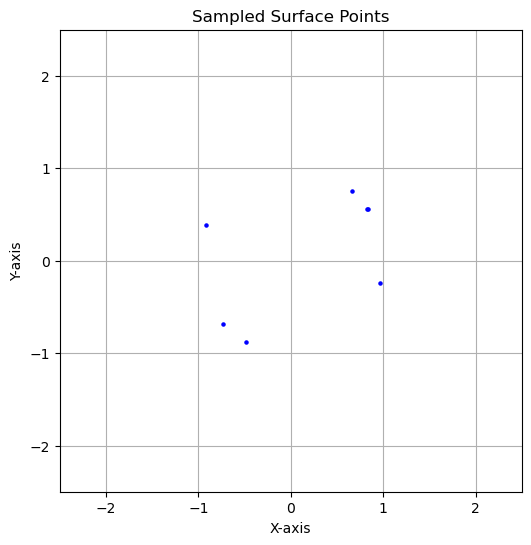

In [12]:
fig = plt.figure(figsize=(6,6))
plt.scatter(samples[:, 0], samples[:, 1], s=5, color='blue')
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Sampled Surface Points')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.grid()
plt.show()

### 3d

In [ ]:
surface = sdfImplicit(fn=sphere_sdf, dim=3)
params = {'center': jnp.array([0.0, 0.0, 0.0]), 'radius': jnp.array(1.0)}

surface_sampler = SurfaceSampler(
    surface.ray_step,
    level_set=surface.level_set,
    dim=surface.dim,
    max_step=1000,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=jnp.inf,
    debug=True,
    n_compactions=1
)

In [15]:
bbox_min = jnp.array([-2.0, -2.0, -2.0])
bbox_max = jnp.array([2.0, 2.0, 2.0])
num_samples = 100
active_states, output_states, active_indices = surface_sampler.sample_surface_points(params, jr.PRNGKey(0), bbox_min, bbox_max, num_samples)

In [17]:
output_states

MultiHitRayOutput(niter=Array([ 76,  25,  17,  15,  74,  16,  60,  52,  15,  19,  16,  17,  11,
        13,  15,  81,  13,  15,  13,  26,  83, 130,  42,  17,  20,  19,
        55,  19, 129,  24,  20,  17,  26,  43,  33,  17,  34,  22,  12,
        50,  19, 121,  60,  18,  16,  15,  19,  16,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0], dtype=int32), ray_origin=Array([[-0.6015435 ,  0.7372631 ,  0.30755258],
       [ 0.4969807 ,  0.8290779 , -0.25620317],
       [-0.1687967 , -0.98387796,  0.05909133],
       [-0.23429497,  0.40287554,  0.88475823],
       [ 0.4129055 , -0.7422047 ,  0.5278647 ],
       [ 0.905633  ,  0.0625941 ,  0.41941738],
       [-0.38503584, -0.02453367, -0.9225755 ],
       [-0.24791117, -0.5365704 ,  0.80661774],
       [ 0

In [19]:
surface_points = gather_hit_points(output_states)

In [20]:
output_states

MultiHitRayOutput(niter=Array([ 76,  25,  17,  15,  74,  16,  60,  52,  15,  19,  16,  17,  11,
        13,  15,  81,  13,  15,  13,  26,  83, 130,  42,  17,  20,  19,
        55,  19, 129,  24,  20,  17,  26,  43,  33,  17,  34,  22,  12,
        50,  19, 121,  60,  18,  16,  15,  19,  16,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0], dtype=int32), ray_origin=Array([[-0.6015435 ,  0.7372631 ,  0.30755258],
       [ 0.4969807 ,  0.8290779 , -0.25620317],
       [-0.1687967 , -0.98387796,  0.05909133],
       [-0.23429497,  0.40287554,  0.88475823],
       [ 0.4129055 , -0.7422047 ,  0.5278647 ],
       [ 0.905633  ,  0.0625941 ,  0.41941738],
       [-0.38503584, -0.02453367, -0.9225755 ],
       [-0.24791117, -0.5365704 ,  0.80661774],
       [ 0

In [22]:

for i in range(output_states.ray_origin.shape[0]):
    ray_origin = output_states.ray_origin[i]
    ray_direction = output_states.ray_direction[i]
    t_values = output_states.t_hits[i, :output_states.hit_counts[i]]
    print(f"Ray {i}:")
    print(f"  Origin: {ray_origin}")
    print(f"  Direction: {ray_direction}")
    print(f"  t values: {t_values}")

Ray 0:
  Origin: [-0.6015435   0.7372631   0.30755258]
  Direction: [ 2.         1.6123723 -1.215918 ]
  t values: [0.]
Ray 1:
  Origin: [ 0.4969807   0.8290779  -0.25620317]
  Direction: [ 1.0915086  -1.9999998   0.15368438]
  t values: [0.]
Ray 2:
  Origin: [-0.1687967  -0.98387796  0.05909133]
  Direction: [-1.675331    1.9999999   0.03383209]
  t values: [5.9604645e-08]
Ray 3:
  Origin: [-0.23429497  0.40287554  0.88475823]
  Direction: [-0.80463576 -1.3558855  -1.9999999 ]
  t values: [0.]
Ray 4:
  Origin: [ 0.4129055 -0.7422047  0.5278647]
  Direction: [ 1.6851687   0.07021832 -2.        ]
  t values: [0.]
Ray 5:
  Origin: [0.905633   0.0625941  0.41941738]
  Direction: [-1.2690319 -1.3801799 -2.       ]
  t values: [0.]
Ray 6:
  Origin: [-0.38503584 -0.02453367 -0.9225755 ]
  Direction: [ 2.        -1.2215796 -0.9498081]
  t values: [0.]
Ray 7:
  Origin: [-0.24791117 -0.5365704   0.80661774]
  Direction: [0.45169508 2.         0.61136866]
  t values: [0.]
Ray 8:
  Origin: [ 0.87

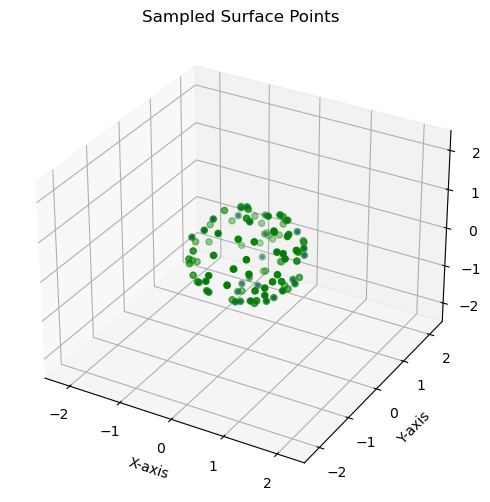

In [21]:
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(surface_points[:, 0], surface_points[:, 1], surface_points[:, 2], s=5, color='blue')
ax.scatter(output_states.ray_origin[:, 0], output_states.ray_origin[:, 1], output_states.ray_origin[:, 2], s=20, color='green', label='Ray Origins')

# for i in range(output_states.ray_origin.shape[0]):
#     ray_origin = output_states.ray_origin[i]
#     ray_direction = output_states.ray_direction[i]
#     t_values = output_states.t_hits[i, :output_states.hit_counts[i]]
#     for t in t_values:
#         hit_point = ray_origin + ray_direction * t
#         ax.plot([ray_origin[0], hit_point[0]], [ray_origin[1], hit_point[1]], [ray_origin[2], hit_point[2]], color='red', alpha=0.5)


ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_zlim(-2.5, 2.5)
ax.set_title('Sampled Surface Points')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Z-axis')
plt.show()

## Neural Network

In [23]:
from typing import NamedTuple

class Params(NamedTuple):
    w1: jnp.ndarray  # [d_in, d_hidden]
    b1: jnp.ndarray  # [d_hidden]
    w2: jnp.ndarray  # [d_hidden, d_hidden]
    b2: jnp.ndarray  # [d_hidden]
    w3: jnp.ndarray  # [d_hidden, d_hidden]
    b3: jnp.ndarray  # [d_hidden]
    w4: jnp.ndarray  # [d_hidden, d_out]
    b4: jnp.ndarray  # [d_out]


def init_params(d_in, d_hidden, d_out, key):
    w1_key, w2_key, w3_key, w4_key, b1_key, b2_key, b3_key, b4_key = jax.random.split(key, num=8)
    return Params(
        w1=jax.random.uniform(key=w1_key, shape=[d_in, d_hidden], minval=-1/math.sqrt(d_in), maxval=1/math.sqrt(d_in)),
        b1=jax.random.uniform(key=b1_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w2=jax.random.uniform(key=w2_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b2=jax.random.uniform(key=b2_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w3=jax.random.uniform(key=w3_key, shape=[d_hidden, d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b3=jax.random.uniform(key=b3_key, shape=[d_hidden], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        w4=jax.random.uniform(key=w4_key, shape=[d_hidden, d_out], minval=-1/math.sqrt(d_hidden), maxval=1/math.sqrt(d_hidden)),
        b4=jax.random.uniform(key=b4_key, shape=[d_out], minval=-1/math.sqrt(d_out), maxval=1/math.sqrt(d_out)),
    )


def neural_network(params, x):
    x = x @ params.w1 + params.b1
    x = jax.nn.swish(x)
    x = x @ params.w2 + params.b2
    x = jax.nn.swish(x)
    x = x @ params.w3 + params.b3
    x = jax.nn.swish(x)
    x = x @ params.w4 + params.b4
    return x

In [24]:
params = init_params(2, 32, 1, key=jax.random.PRNGKey(1))
LEARNING_RATE = 5e-4
STEPS = 2000
trained_params = init_params(2, 32, 1, key=jax.random.PRNGKey(2))
optim = optax.adam(LEARNING_RATE)

In [25]:
def sdf_circle_jax(X: jnp.ndarray, radius) -> jnp.ndarray:
    return jnp.sqrt(jnp.sum(X**2, axis=-1)) - radius

def train(model, params, optim, ndim, radius, n_steps, subkey):
    opt_state = optim.init(params)

    def loss_fn(params, X, radius):
        pred_y = jax.vmap(model, in_axes=(None, 0))(params, X)
        true_y = jax.vmap(lambda x: sdf_circle_jax(x, radius=radius))(X)
        return jax.numpy.mean((pred_y[:, 0] - true_y) ** 2)

    @partial(jax.jit, static_argnames=('radius'))
    def step(params, opt_state, X, radius):
        loss, grads = jax.value_and_grad(loss_fn, argnums=0)(params, X, radius)
        update, opt_state = optim.update(grads, opt_state)
        params = optax.apply_updates(params, update)
        return params, opt_state, loss
    
    def point_sampler(key):
        key, subkey = jax.random.split(key)
        return jax.random.uniform(subkey, (10000, ndim), minval=-2, maxval=2), subkey
    
    for iter in range(0, n_steps):
        XY, subkey = point_sampler(subkey)
        params, opt_state, loss = step(params, opt_state, XY, radius)
        if iter % 100 == 0:
            print(f"Iteration {iter}, loss: {loss}")
    return params

In [26]:
trained_params = train(
    model=neural_network,
    params=params,
    optim=optim,
    ndim=2,
    radius=1.0,
    n_steps=STEPS,
    subkey=jax.random.PRNGKey(0)
)

Iteration 0, loss: 0.32687920331954956
Iteration 100, loss: 0.0737849622964859
Iteration 200, loss: 0.007417687680572271
Iteration 300, loss: 0.0032860487699508667
Iteration 400, loss: 0.0022620533127337694
Iteration 500, loss: 0.0020890086889266968
Iteration 600, loss: 0.001902820891700685
Iteration 700, loss: 0.0017351142596453428
Iteration 800, loss: 0.0014159224228933454
Iteration 900, loss: 0.0011936479713767767
Iteration 1000, loss: 0.0009755125502124429
Iteration 1100, loss: 0.0007827366353012621
Iteration 1200, loss: 0.0005688625969924033
Iteration 1300, loss: 0.0004603156994562596
Iteration 1400, loss: 0.0003918042639270425
Iteration 1500, loss: 0.0003488507936708629
Iteration 1600, loss: 0.00030453980434685946
Iteration 1700, loss: 0.00029546525911428034
Iteration 1800, loss: 0.0003116780426353216
Iteration 1900, loss: 0.00028660500538535416


In [27]:
res = 100

mesh_x, mesh_y = mesh_2d(res, ((-2.0, 2.0), (-2.0, 2.0)))

X_jnp = mesh_to_vec_2d(mesh_x, mesh_y)
Z_nn = jax.vmap(neural_network, in_axes=(None, 0))(trained_params, X_jnp)

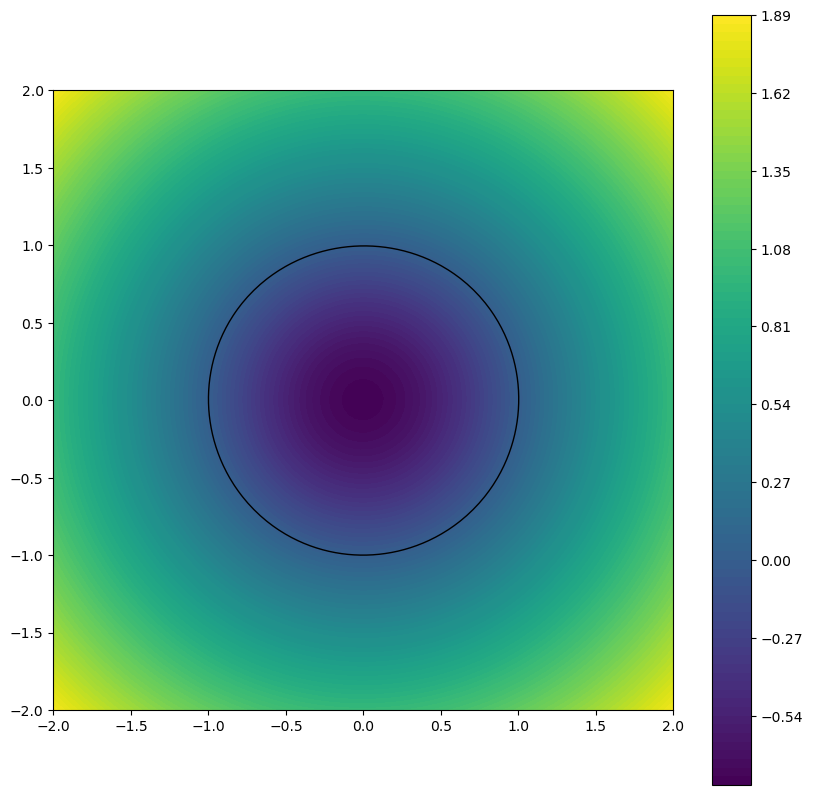

In [28]:
fig = plt.figure(figsize=(10, 10))

ax = fig.add_subplot(111)
ax.set_aspect('equal')
"""
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_xlim(-1.1, -0.9)
ax.set_ylim(-0.1, 0.1)
"""

contourf = ax.contourf(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=100, cmap='viridis')
ax.contour(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=0, colors='black', linewidths=1)
fig.colorbar(contourf, ax=ax, orientation='vertical')

In [29]:
jnp_surface = jnpboundedImplicit(
    fn=lambda x: neural_network(trained_params, x),
    dim=2,
    autobounds_max_degree=2,
    level_set=0.0,
)

In [30]:
jnp_surface_sampler = SurfaceSampler(
    jnp_surface.ray_step,
    level_set=jnp_surface.level_set,
    dim=jnp_surface.dim,
    max_step=1000,
    epsilon=1e-5,
    max_hits=20,
    init_trust_region_size=0.5,
    n_compactions=2,
    debug=True,
)


In [31]:
jnp_surface.fn(jnp.array([0.0, 0.0]))

Array([-0.77065456], dtype=float32)

In [32]:
jnp_surface.taylor_bounds(jnp.array([0.0, 0.0]), x_trust_region=None, trust_region_size=jnp.array(0.5)).polynomial_enclosure[0]

Array([-0.77065456], dtype=float32)

In [33]:
jnp_surface.ray_step(
    params=None,
    ray_origin=jnp.array([0.0, 0.0]),
    ray_direction=jnp.array([1.0, 0.0]),
    trust_region_size=jnp.array(0.5),
)

(Array([-0.77065456], dtype=float32),
 Array([0.25], dtype=float32),
 Array([ True], dtype=bool))

In [38]:
active_states, output_states, active_indices = jnp_surface_sampler.sample_surface_points(
    params=None,
    key=jax.random.PRNGKey(42),
    bbox_min=jnp.array([-2.0, -2.0]),
    bbox_max=jnp.array([2.0, 2.0]),
    num_rays=1000,
)

In [39]:
surface_samples = gather_hit_points(output_states)

In [40]:
output_states

MultiHitRayOutput(niter=Array([28, 25, 32, 22, 21, 21, 20, 31, 20, 18, 27, 29, 22, 14, 21, 11, 20,
       25, 35, 31, 17, 21, 20, 27,  4, 32, 21, 26, 17, 16, 21, 19, 14, 32,
       23, 34, 14, 32, 14, 23, 15, 17, 25, 18, 32, 28, 38, 35, 29, 33, 23,
       18, 31, 26, 54, 24,  5, 27, 14, 24, 32, 31, 24, 21, 21, 18, 13, 30,
       21, 35, 32, 33, 19, 22, 16, 22, 17, 16, 24, 20, 14, 18,  1, 30, 25,
       19, 13, 10, 18, 17, 11, 18, 11, 17, 21, 19, 11, 25, 22, 19, 24, 21,
        1,  6, 30, 42, 14, 28, 24, 10, 33, 19, 31, 11,  2, 24, 18, 23, 23,
       31, 22, 25, 32, 10, 20, 26, 16, 29, 23, 14, 10, 26, 19, 18, 14, 18,
        9, 24,  9,  5, 22, 17, 29, 17, 19, 26, 17, 10, 11, 15, 24, 18, 10,
       25, 34, 15, 17, 20, 26, 24, 14, 16,  3, 17,  6,  7,  3, 13, 16, 25,
       22,  4, 20, 24, 18, 15, 22,  2,  8, 16, 30, 14, 19, 24, 19, 17, 19,
       20, 22, 34, 31, 11, 32, 26, 24,  5, 17, 11, 18, 26, 11, 22, 26, 26,
       23, 22, 44, 18, 29, 32, 25, 35, 22, 18, 12, 29, 22, 18, 31, 23, 30,
 

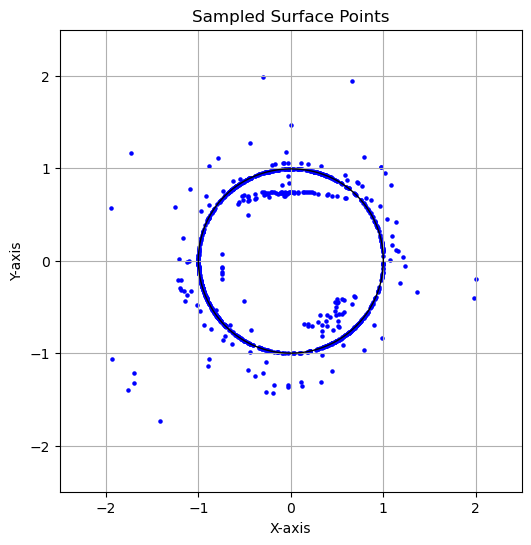

In [41]:
fig = plt.figure(figsize=(6,6))
plt.contour(mesh_x, mesh_y, Z_nn.reshape(mesh_x.shape), levels=0, colors='black', linewidths=1)

plt.scatter(surface_samples[:, 0], surface_samples[:, 1], s=5, color='blue')
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.title('Sampled Surface Points')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.grid()
plt.show()